# CHLA-Z 5: How the in situ and satellite data compare

**Author:** Eli Holmes (NOAA)<br>
Last updated: November 23, 2026

> **What this notebook is.** A look at the released CHLA-Z tables: how
> in situ surface chlorophyll (BGC-Argo, OOI) compares with PACE, why the
> time of day matters, and how OLCI and PACE overlap. It is **not** a methods
> notebook (those are 01–04) and **not** model training. It only reads the
> tables in `datasets/chla_z/data/`, so it runs in seconds.

| # | Notebook | |
|---|---|---|
| 1 | 01-argo-retrieval-qc | BGC-Argo retrieval, QC, depth bins |
| 2 | 02-ooi-retrieval-qc | OOI retrieval, QC, 3 h solar-time windows, Sauzède correction |
| 3 | 03-pace-matchups | PACE Rrs, chlor_a, Kd matchups |
| 4 | 04-olci-matchups | Sentinel-3 OLCI Rrs matchups |
| 5 | **05-compare-datasets** | how the datasets compare |

The in situ and satellite chlorophyll estimates measure different things and
are not expected to agree. In situ CHLA is fluorescence from a sensor at one
point, converted to chlorophyll. PACE `chlor_a` is computed from the colour of
the water (Rrs band ratios) over a 4 km cell, weighted toward the first
optical depth. They are correlated, and the ways they differ are what a model
has to learn.

In [1]:
import sys

if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chla_z_build as b

D = b.DATA_DIR


def surface_vs_pace(platform):
    """Rows with positive in situ 0-10 m CHLA and PACE chlor_a, with log10
    values, the bias log10(PACE) - log10(in situ), and local mean solar hour."""
    df = pd.read_parquet(D / f"CHLA_{platform}_profiles_plus_PACE.parquet")
    tcol, loncol = ("TIME", "LONGITUDE") if platform == "argo" else ("time", "lon")
    df = df[(df["CHLA_0_10"] > 0) & (df["pace_chlor_a"] > 0)].copy()
    t = pd.to_datetime(df[tcol], utc=True)
    df["solar_hour"] = (t.dt.hour + t.dt.minute / 60 + df[loncol] / 15.0) % 24
    df["log_insitu"] = np.log10(df["CHLA_0_10"])
    df["log_pace"] = np.log10(df["pace_chlor_a"])
    df["bias"] = df["log_pace"] - df["log_insitu"]
    return df


argo = surface_vs_pace("argo")
ooi = surface_vs_pace("ooi")
ooi["instrument"] = ooi["profile_id"].str.rsplit("_", n=1).str[0]
print(f"Argo: {len(argo)} profiles from {argo['PLATFORM_NUMBER'].nunique()} floats")
print(f"OOI:  {len(ooi)} 3 h windows from {ooi['instrument'].nunique()} instruments")

Argo: 9344 profiles from 826 floats
OOI:  10399 3 h windows from 12 instruments


Only rows with chlorophyll in the 0–10 m bin count here. For OOI that leaves
the instruments that sample near the surface (profilers and near-surface
moorings). Several 3 h windows of one instrument-day share one PACE pixel, so
the OOI points are less independent than their number suggests.

## 1. Surface chlorophyll: in situ vs PACE

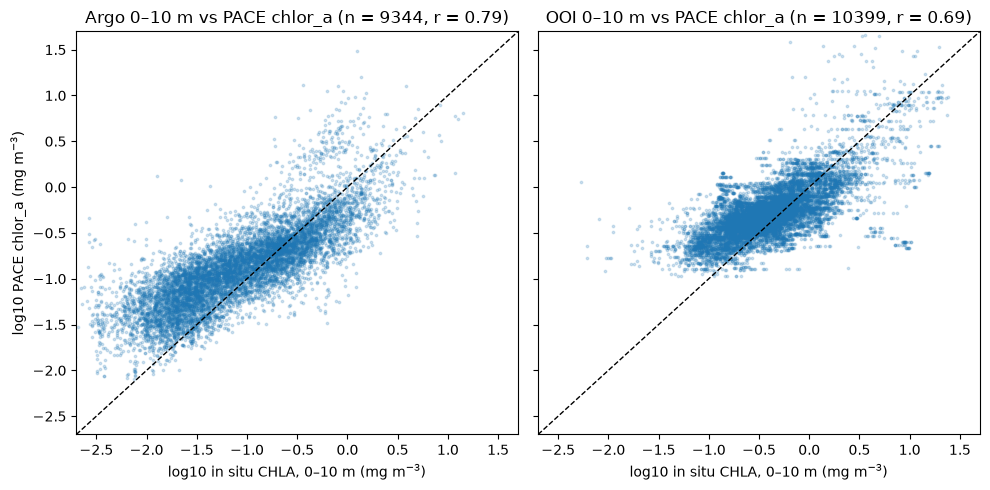

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, (name, df) in zip(axes, [("Argo", argo), ("OOI", ooi)]):
    ax.scatter(df["log_insitu"], df["log_pace"], s=3, alpha=0.2)
    lims = [-2.7, 1.7]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    r = np.corrcoef(df["log_insitu"], df["log_pace"])[0, 1]
    ax.set_title(f"{name} 0–10 m vs PACE chlor_a (n = {len(df)}, r = {r:.2f})")
    ax.set_xlabel("log10 in situ CHLA, 0–10 m (mg m$^{-3}$)")
axes[0].set_ylabel("log10 PACE chlor_a (mg m$^{-3}$)")
plt.tight_layout()

The median bias, log10(PACE) − log10(in situ), by in situ chlorophyll:

In [3]:
bins = [-3, -1.5, -1, -0.5, 0, 0.5, 1, 2]
pd.DataFrame({
    name: df.groupby(pd.cut(df["log_insitu"], bins), observed=False)["bias"].median()
    for name, df in [("Argo", argo), ("OOI", ooi)]
}).round(2).rename_axis("log10 in situ CHLA")

,Argo,OOI
log10 in situ CHLA,,
"(-3.0, -1.5]",0.53,1.04
"(-1.5, -1.0]",0.27,0.49
"(-1.0, -0.5]",0.02,0.29
"(-0.5, 0.0]",-0.15,0.04
"(0.0, 0.5]",-0.29,-0.20
"(0.5, 1.0]",-0.48,-0.30
"(1.0, 2.0]",-0.35,-0.37


A familiar pattern: PACE reads higher than the in situ sensor in clear, low
chlorophyll water and lower where chlorophyll is high. Note the ranges, too.
Argo floats are mostly in the open ocean: half the matched profiles are below
about 0.08 mg m⁻³ and very few are above 1 mg m⁻³, so blooms are barely
sampled. OOI's coastal and high-latitude sites fill in more of the upper
range.

In [4]:
pd.DataFrame({name: (10 ** df["log_insitu"]).describe(percentiles=[0.05, 0.5, 0.95])
              for name, df in [("Argo", argo), ("OOI", ooi)]}).round(3)

,Argo,OOI
count,9344.000,10399.000
mean,0.241,0.832
std,0.536,1.700
min,0.000,0.005
5%,0.009,0.089
50%,0.077,0.404
95%,0.956,2.596
max,14.292,24.307


## 2. Time of day: quenching in the in situ data

In bright light, phytoplankton shed absorbed energy as heat instead of
fluorescence (non-photochemical quenching, NPQ). A fluorometer near the
surface then reads low around midday. PACE is a daily composite with no
per-pixel overpass time, so the satellite side does not change with the
profile's time of day: any pattern in the bias by solar hour comes from the
in situ side.

Argo `CHLA_ADJUSTED` has an NPQ correction; OOI has none. Below is the
median bias in 3 h bins of local mean solar time, with the interquartile
range.

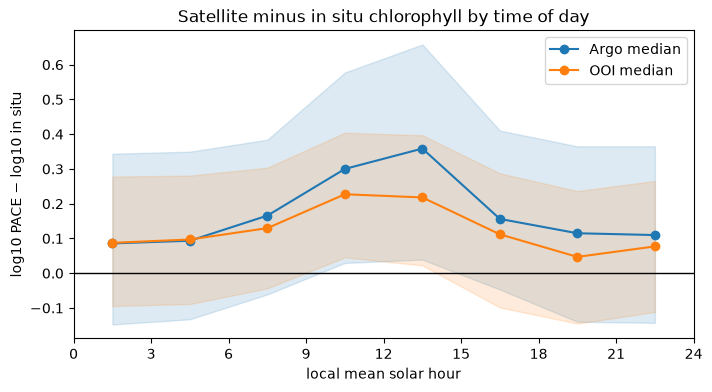

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, df, color in [("Argo", argo, "tab:blue"), ("OOI", ooi, "tab:orange")]:
    g = df.groupby((df["solar_hour"] // 3 * 3).astype(int))["bias"]
    q = g.quantile([0.25, 0.5, 0.75]).unstack()
    x = q.index + 1.5
    ax.plot(x, q[0.5], "-o", color=color, label=f"{name} median")
    ax.fill_between(x, q[0.25], q[0.75], color=color, alpha=0.15)
ax.axhline(0, color="k", lw=1)
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("local mean solar hour")
ax.set_ylabel("log10 PACE − log10 in situ")
ax.set_title("Satellite minus in situ chlorophyll by time of day")
ax.legend();

In [6]:
pd.DataFrame({name: df.groupby((df["solar_hour"] // 3 * 3).astype(int))["bias"]
              .agg(["median", "count"]).stack()
              for name, df in [("Argo", argo), ("OOI", ooi)]}).unstack().round(2)

Argo            OOI        
           median   count median   count
solar_hour                              
0            0.09   924.0   0.09  1334.0
3            0.09   949.0   0.10  1326.0
6            0.17   959.0   0.13  1340.0
9            0.30  2172.0   0.23  1402.0
12           0.36  1435.0   0.22  1306.0
15           0.16   928.0   0.11  1308.0
18           0.11   938.0   0.05  1035.0
21           0.11  1039.0   0.08  1348.0

Both platforms show the same shape. At night the median bias is about
0.1 log10. Between 09 and 15 h solar time it is about 0.3–0.36 for Argo and
about 0.22 for OOI. Relative to the satellite, the in situ value at midday is
roughly 45% (Argo) and 25% (OOI) lower than at night. Two independent data
sets agree, and the Argo pattern is there even after its NPQ correction.

The two platforms sample the day differently. Argo floats surface on a
schedule, and many surface near local noon, so midday is over-represented in
the Argo table. OOI rows are 3 h windows around the clock, so every hour is
about equally represented. This is why the tables carry the profile time
(and a model should carry `solar_hour`): it lets a model learn the quenching
effect instead of absorbing it as noise.

## 3. Water clarity

Is the bias also related to how clear the water is? To keep quenching out of
it, use only night-time profiles (solar hour before 8 or after 16).
1/Kd(490) is roughly the depth (m) of the layer the satellite sees.

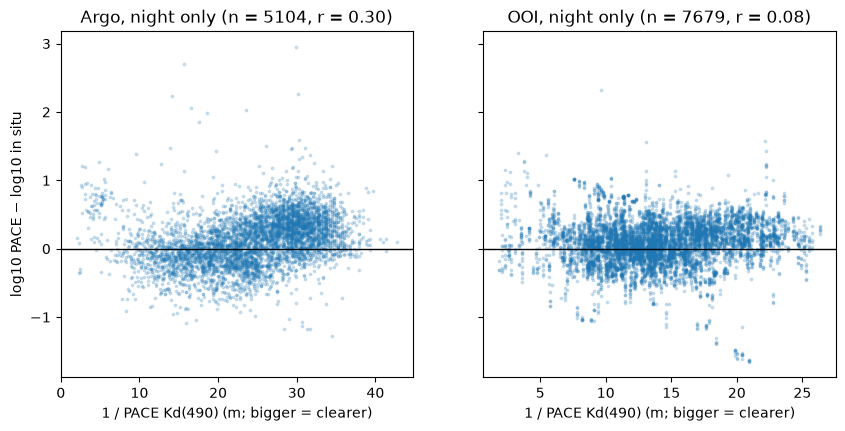

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, (name, df) in zip(axes, [("Argo", argo), ("OOI", ooi)]):
    night = df[~df["solar_hour"].between(8, 16) & df["pace_Kd_490"].notna()]
    ax.scatter(1 / night["pace_Kd_490"], night["bias"], s=3, alpha=0.2)
    r = np.corrcoef(1 / night["pace_Kd_490"], night["bias"])[0, 1]
    ax.axhline(0, color="k", lw=1)
    ax.set_title(f"{name}, night only (n = {len(night)}, r = {r:.2f})")
    ax.set_xlabel("1 / PACE Kd(490) (m; bigger = clearer)")
axes[0].set_ylabel("log10 PACE − log10 in situ");

For Argo the satellite reads higher in clearer water, which is the
low-chlorophyll pattern of section 1 seen through Kd (Kd and chlor_a are
themselves strongly related). The OOI sites span less of the clear-water
range and show little trend.

## 4. OLCI and PACE

The `_plus_OLCI` tables hold every profile on a day with an OLCI file, with
flags for whether it also has a PACE match. Through September 2026 (both
sensors available):

In [8]:
rows = {}
for platform in b.PLATFORMS:
    o = pd.read_parquet(D / f"CHLA_{platform}_profiles_plus_OLCI.parquet")
    o = o[o["olci_day"] < "20261001"]
    olci_ok = o[[f"olci_Rrs_{nm}" for nm in b.OLCI_BANDS]].notna().all(axis=1)
    rows[platform] = {"profiles": len(o),
                      "OLCI, all 11 bands": int(olci_ok.sum()),
                      "PACE Rrs": int(o["pace_Rrs_valid"].sum()),
                      "both": int((olci_ok & o["pace_Rrs_valid"]).sum()),
                      "either": int((olci_ok | o["pace_Rrs_valid"]).sum())}
pd.DataFrame(rows).T

,profiles,"OLCI, all 11 bands",PACE Rrs,both,either
argo,57544,12535,9187,4935,16787
ooi,94265,23900,21823,13484,32239


OLCI gives more valid matchups than PACE, and only part of each sensor's
valid profiles are valid in the other, so using both adds data. Part of the
difference is the matching rule, not the sensor: PACE uses a 24 h window
from the file's start time, OLCI the profile's UTC calendar day.

Where both are valid, the two sensors' Rrs at similar bands:

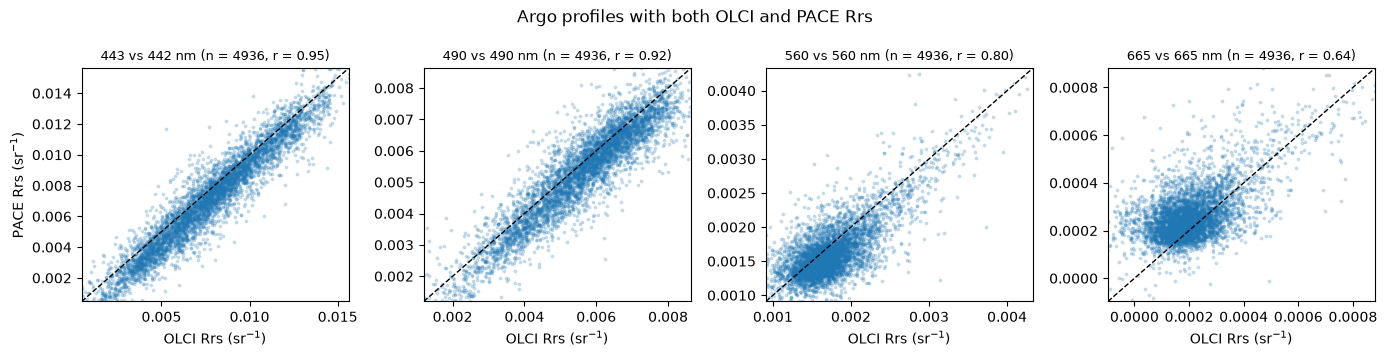

In [9]:
argo_olci = pd.read_parquet(D / "CHLA_argo_profiles_plus_OLCI.parquet")
argo_pace = pd.read_parquet(D / "CHLA_argo_profiles_plus_PACE.parquet",
                            columns=["profile_id", "pace_Rrs_442", "pace_Rrs_490",
                                     "pace_Rrs_560", "pace_Rrs_665"])
both = argo_olci[argo_olci["pace_Rrs_valid"]].merge(argo_pace, on="profile_id")
pairs = [(443, 442), (490, 490), (560, 560), (665, 665)]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (o_nm, p_nm) in zip(axes, pairs):
    x, y = both[f"olci_Rrs_{o_nm}"], both[f"pace_Rrs_{p_nm}"]
    ok = x.notna() & y.notna()
    ax.scatter(x[ok], y[ok], s=3, alpha=0.2)
    lo, hi = np.nanpercentile(np.r_[x[ok], y[ok]], [0.5, 99.5])
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_title(f"{o_nm} vs {p_nm} nm (n = {ok.sum()}, r = {np.corrcoef(x[ok], y[ok])[0, 1]:.2f})",
                 fontsize=9)
    ax.set_xlabel("OLCI Rrs (sr$^{-1}$)")
axes[0].set_ylabel("PACE Rrs (sr$^{-1}$)")
fig.suptitle("Argo profiles with both OLCI and PACE Rrs")
plt.tight_layout()

The sensors agree closely in the blue (r ≈ 0.95 at 443 nm) and less well
toward the red, where Rrs in open-ocean water is small, so differences
between the sensors are large relative to the signal (r ≈ 0.6 at 665 nm).

## Where to go next

- How each table is made: notebooks 01–04, and `datasets/chla_z/README.md`.
- Rules and decisions behind the tables: `claude/notes/chla-z-rebuild-2026-11.md`.
- When training on the OOI tables, group train/test splits by instrument:
  windows of one instrument-day share a satellite pixel.

### Earlier notebooks

These notebooks replace `argopy.ipynb`, `ooi.ipynb` and `argo-matchups.ipynb`,
which built the tables before the build moved to `build.py`. They are kept
at the release tag
[`2026_11_23`](https://github.com/fish-pace/fish-pace-datasets/tree/2026_11_23/datasets/chla_z/notebooks),
or locally with `git checkout 2026_11_23 -- datasets/chla_z/notebooks/argopy.ipynb`.